In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "src")); sys.path.insert(0, str(ROOT / "tests"))
TABLES, FIGS, PROC = ROOT / "reports/tables", ROOT / "reports/figures", ROOT / "data/processed"
from olpred.viz import style; style.apply()
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

def show(name, width=820):
    display(Image(filename=str(FIGS / name), width=width))

def table(name, **kw):
    return pd.read_csv(TABLES / name, **kw)


# 06 — Interpretability
Grouped permutation importance, exact linear contributions, partial dependence. Report: `docs/phase7_interpretability.md`.

In [2]:
table("phase7_family_permutation_importance.csv").round(4)

,model,family,n_columns,delta_log_loss,sd
0,LogReg,Elo rating,4,0.0496,0.0049
1,LogReg,Squad market value,6,0.0236,0.0024
2,LogReg,Recent form (3/5/10 matches),30,0.0072,0.0015
3,LogReg,xG proxy,18,0.0032,0.0011
4,LogReg,Shots (on target / against),18,0.0030,0.0012
5,LogReg,Fatigue / schedule,6,0.0008,0.0005
6,LogReg,Venue form (home/away),9,0.0003,0.0006
7,LogReg,League table,9,-0.0001,0.0005
8,Gradient boosting,Squad market value,6,0.0284,0.0024
9,Gradient boosting,Elo rating,4,0.0260,0.0032


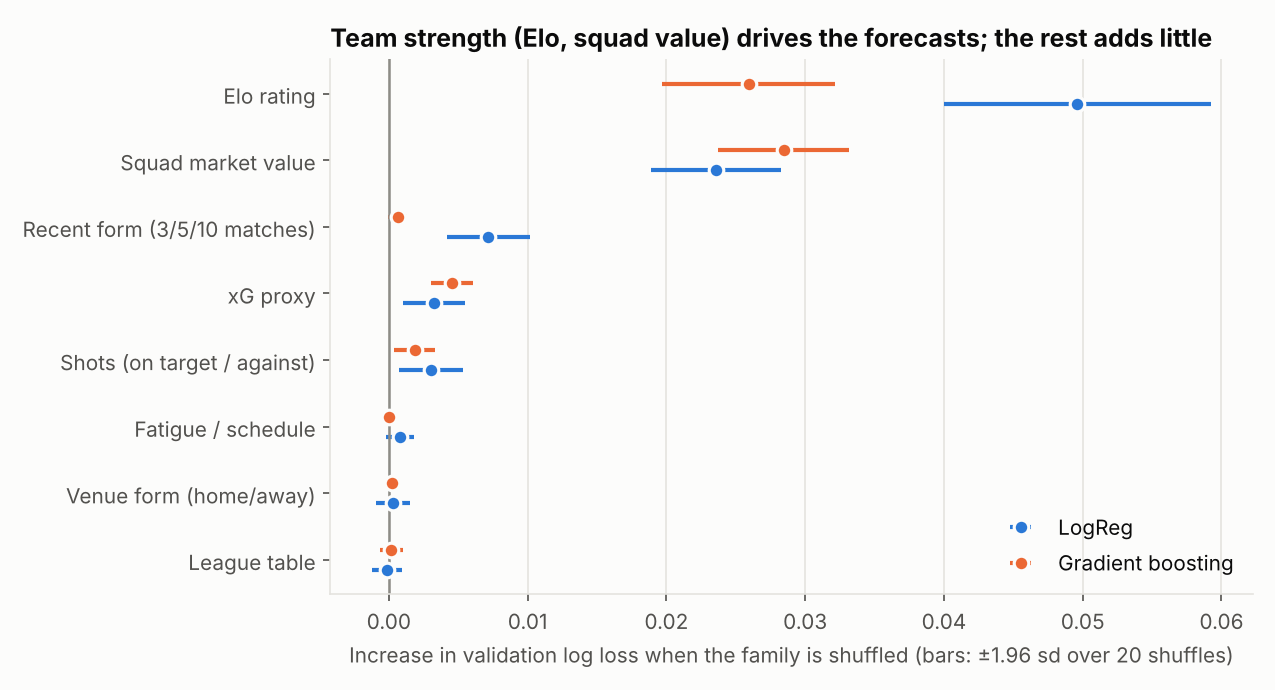

In [3]:
show("phase7_family_importance.png")

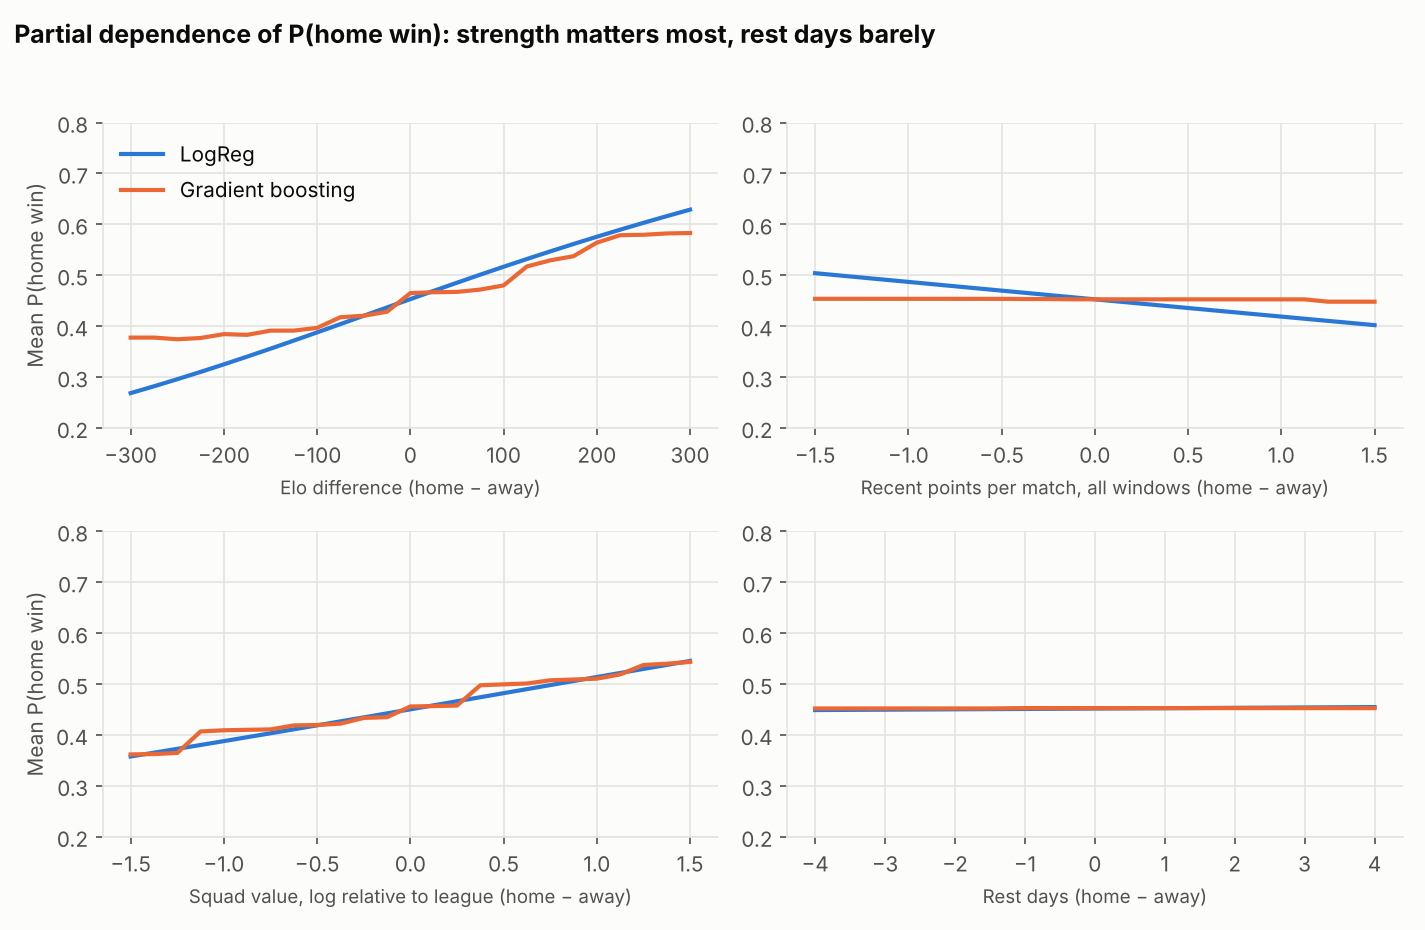

In [4]:
show("phase7_partial_dependence.png", 760)

### Largest standardised coefficients (logit home − logit away)

In [5]:
table("phase7_logreg_coefficients.csv").head(12).round(3)

,feature,coef_home_minus_away,coef_draw,family
0,elo_diff,0.214,-0.015,Elo rating
1,elo_away,-0.156,-0.022,Elo rating
2,elo_home,0.152,-0.043,Elo rating
3,d_sv_top11_rel,0.146,0.000,Squad market value
4,elo_exp_home,0.141,0.040,Elo rating
5,h_sv_top11_rel,0.111,-0.015,Squad market value
6,a_sv_top11_rel,-0.107,-0.016,Squad market value
7,d_pos_norm,0.068,0.002,League table
8,d_gdpg_season,0.060,-0.009,League table
9,a_xg_10,-0.056,0.005,xG proxy


### The history-depth episode (legacy 106-column model)
The first analysis showed weight on `n_prior`, a calendar clock. Importance of that family in the legacy model vs. the final feature set:

In [6]:
leg = table("phase7_legacy_family_permutation_importance.csv"); cur = table("phase7_family_permutation_importance.csv")
pd.concat({"legacy (106 columns)": leg.query("model=='LogReg'").set_index("family").delta_log_loss,
           "final (100 columns)": cur.query("model=='LogReg'").set_index("family").delta_log_loss}, axis=1).round(4)

,legacy (106 columns),final (100 columns)
family,,
Elo rating,0.0445,0.0496
Squad market value,0.0274,0.0236
Recent form (3/5/10 matches),0.0060,0.0072
xG proxy,0.0031,0.0032
Shots (on target / against),0.0029,0.0030
History depth,0.0010,NaN
Fatigue / schedule,0.0006,0.0008
Venue form (home/away),0.0003,0.0003
League table,-0.0001,-0.0001
